In [ ]:
from dataclasses import dataclass
from pathlib import Path
from collections import defaultdict
from typing import Any, Dict, List, Tuple
from pprint import pprint
import ast

from inspect_ai.log import read_eval_log 
from inspect_ai.log import EvalSample
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def list_all_logs_in_dir(dir_path: Path):
    files_path = []
    for item in dir_path.iterdir():
        if item.is_file() and item.suffix == ".eval":
            files_path.append(Path(item))
    return files_path


def parse_grading_line(line: str) -> dict:
    try:
        start = line.index("{")
        end = line.rindex("}")
        dict_str = line[start:end+1]
        return ast.literal_eval(dict_str)
    except (ValueError, SyntaxError):
        return {}


@dataclass
class EvalRun:
    task_name: str
    model_name: str
    split: str
    padding_type: str | None
    padding_length: int
    random_seed: int
    metrics_overall: dict
    metrics_per_sample: list[dict]
    num_turns_per_sample: list[int]
    num_turns_per_sample_avg: dict
    grading_breakdown_per_sample: list[dict[str, Any]]
    log_path: Path
    task_args: dict[str, Any]
    _samples: list[EvalSample] | None

    @classmethod
    def from_log_file(cls, log_path: Path) -> "EvalRun":
        logs = read_eval_log(log_path)
        md = []
        num_turns_per_sample = []
        for idx, sample in enumerate(logs.samples):
            score = logs.reductions[0].samples[idx]
            md.append(
                {
                    "id": sample.metadata["id"], 
                    "id_original": sample.metadata["id_original"], 
                    "hint_included": sample.metadata["hint_included"], 
                    "detailed_prompt": sample.metadata["detailed_prompt"],
                    'name': sample.metadata["name"],
                    'category': sample.metadata["category"],
                    "score_obj": score,
                    "score": score.value["score"]},
            )
            num_turns_per_sample.append(len(sample.messages))
        task_args = logs.eval.task_args_passed
        task_args["padding_token_length"] = task_args.get("padding_token_length", task_args.get("padding_length", None)) 
        return cls(
            task_name=logs.plan.steps[0].params["task_name"],
            model_name = logs.eval.model,
            split=task_args["split"],
            random_seed=task_args["random_seed"],
            padding_type=task_args["padding_type"],
            padding_length= 0 if task_args["padding_token_length"] is None else task_args["padding_token_length"],
            metrics_overall=logs.results.scores[0].metrics,
            metrics_per_sample=md,
            log_path=log_path,
            task_args=task_args,
            grading_breakdown_per_sample=[parse_grading_line(sample.explanation) for sample in logs.reductions[0].samples],
            num_turns_per_sample= num_turns_per_sample,
            num_turns_per_sample_avg={"num_turns_avg" : np.mean(num_turns_per_sample)},
            _samples = logs.samples
        )

    @property
    def metrics_per_sample_df(self) -> pd.DataFrame:
        return pd.DataFrame(self.metrics_per_sample)



@dataclass
class EvalRunRandomSeedAgg:
    task_name: str
    model_name: str
    split: str
    padding_type: str | None
    padding_length: int
    random_seeds: list[int]
    metrics_overall: list[dict]
    num_turns_per_sample: list
    num_turns_per_sample_avg: list[dict]
    metrics_per_sample: list[list[dict]]
    grading_breakdown_per_sample: list[list[dict[str, Any]]]
    log_pathes: list[Path]
    task_args: dict[str, Any]
    list_of_evals: list[EvalRun]

    @classmethod
    def from_eval_run_list(cls, evals: list[EvalRun]) -> "EvalRunRandomSeedAgg":
        return cls(
            task_name=evals[0].task_name,
            model_name =evals[0].model_name,
            split=evals[0].split,
            random_seeds=[eval.random_seed for eval in evals],
            padding_type=evals[0].padding_type,
            padding_length=evals[0].padding_length,
            metrics_overall=[eval.metrics_overall for eval in evals],
            metrics_per_sample=[eval.metrics_per_sample for eval in evals],
            log_pathes=[eval.log_path for eval in evals],
            task_args=evals[0].task_args,
            list_of_evals=evals,
            num_turns_per_sample=[eval.num_turns_per_sample for eval in evals],
            num_turns_per_sample_avg=[eval.num_turns_per_sample_avg for eval in evals],
            grading_breakdown_per_sample=[eval.grading_breakdown_per_sample for eval in evals],
        )

    @property
    def metrics_overall_agg(self) -> dict[str, list]:
        return self._agg_dicts(self.metrics_overall)

    def _agg_dicts(self, list_of_dicts: list[dict]) -> dict[str, Any]:
        aggregated = defaultdict(list)
        for d in list_of_dicts:
            for key, value in d.items():
                aggregated[key].append(value.value)
        return dict(aggregated)

    @property
    def metrics_num_turns_agg(self) -> list: 
        aggregated = defaultdict(list)
        for d in self.num_turns_per_sample_avg:
            for key, value in d.items():
                aggregated[key].append(float(value))
        return dict(aggregated)["num_turns_avg"]

def agg_rs_results(dir_path: str) -> EvalRunRandomSeedAgg:
    pathes = list_all_logs_in_dir(Path(dir_path))
    return  EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in pathes])

In [ ]:
def aggregate_histograms(
    runs: List[List[int]],
    bins: np.ndarray | None = None,
    density: bool = True
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Aggregate histograms across multiple seeds (runs) of one experiment.

    runs: list of seeds; each seed is a list of integer 'turns per sample'
    bins: optional shared bin edges; if None, computed from data (integer bins)
    density: if True, return probabilities; else return counts

    Returns:
        mean_hist: mean histogram across seeds (probabilities if density=True)
        std_hist:  std across seeds (same scale as mean_hist)
        bins:      the bin edges used
    """
    if not runs:
        raise ValueError("runs is empty")

    # Build bins if not provided (integer bins covering all observed values)
    if bins is None:
        all_vals = [v for run in runs for v in run]
        if len(all_vals) == 0:
            raise ValueError("All runs are empty")
        vmin = int(np.floor(min(all_vals)))
        vmax = int(np.ceil(max(all_vals)))
        # integer bins, centered at k+0.5
        bins = np.arange(vmin - 0.5, vmax + 1.5, 1.0)

    hists = []
    for run in runs:
        hist, _ = np.histogram(run, bins=bins, density=density)
        hists.append(hist)

    hists = np.asarray(hists)
    mean_hist = hists.mean(axis=0)
    std_hist = hists.std(axis=0, ddof=1) if len(hists) > 1 else np.zeros_like(mean_hist)
    return mean_hist, std_hist, bins


def plot_mean_histograms(
    experiments: Dict[str, List[List[int]]],
    bins: np.ndarray | None = None,
    density: bool = True,
    with_std: bool = True
) -> Dict[str, dict]:
    """
    Plot mean histogram per experiment. Returns a dict with per-experiment stats.

    experiments: {experiment_name: [seed1_turns, seed2_turns, ...]}
    bins: optional shared bin edges for all experiments; if None, computed globally
    density: if True, plot probability mass; else plot mean counts
    with_std: if True, plot ±1 std as a filled band

    Returns:
        stats: {name: {"mean": mean_hist, "std": std_hist, "bins": bins}}
    """
    if not experiments:
        raise ValueError("experiments is empty")

    # If bins not given, compute a global integer binning across all experiments
    if bins is None:
        all_vals = []
        for runs in experiments.values():
            for run in runs:
                all_vals.extend(run)
        if len(all_vals) == 0:
            raise ValueError("All experiments are empty")
        vmin = int(np.floor(min(all_vals)))
        vmax = int(np.ceil(max(all_vals)))
        bins = np.arange(vmin - 0.5, vmax + 1.5, 1.0)

    bin_centers = (bins[:-1] + bins[1:]) / 2.0

    plt.figure(figsize=(8, 5))
    stats = {}

    for name, runs in experiments.items():
        mean_hist, std_hist, _ = aggregate_histograms(runs, bins=bins, density=density)
        stats[name] = {"mean": mean_hist, "std": std_hist, "bins": bins}

        # Use a line over integer-centered bins (clean overlay for multiple experiments)
        plt.plot(bin_centers, mean_hist, marker="o", label=name)
        if with_std and np.any(std_hist > 0):
            upper = mean_hist + std_hist
            lower = mean_hist - std_hist
            lower = np.clip(lower, a_min=0, a_max=None)  # keep non-negative for probs/counts
            plt.fill_between(bin_centers, lower, upper, alpha=0.2)

    plt.xlabel("Turns per sample")
    plt.ylabel("Probability" if density else "Mean count")
    plt.title("Mean histogram per experiment (aggregated across seeds)")
    plt.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)
    plt.legend(title="Experiment")
    plt.tight_layout()
    plt.show()

    return stats


# No padding with many random seeds

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def plot_dict_with_rs(dict_with_rs, title: str = "", xlabel: str = "", ylabel: str="score", connect_keys: bool = False, color: str ="blue") -> None:
    """
    dict_with_rs: {key (str or any hashable): [float, float, ...]}
    Plots raw runs (gray dots) + mean with ±SE error bars.
    Preserves the insertion order of keys for x-axis.
    """
    # Collect categories in insertion order
    cats = [k for k in dict_with_rs.keys()]

    # Compute stats in that order
    means, errs = [], []
    all_x_pos, all_y = [], []

    for i, k in enumerate(cats):
        runs = np.asarray(dict_with_rs[k], dtype=float)
        runs = runs[~np.isnan(runs)]  # drop NaNs if any
        if runs.size == 0:
            # skip empty categories
            continue

        mean = runs.mean()
        sd = runs.std(ddof=1) if runs.size > 1 else 0.0
        se = sd / np.sqrt(runs.size) if runs.size > 0 else 0.0

        means.append(mean)
        errs.append(se)

        all_x_pos.extend([i] * runs.size)
        all_y.extend(runs.tolist())

    x_pos = np.arange(len(means))  # numeric positions for plotting

    plt.figure(figsize=(7, 4.5))

    # Raw points
    plt.scatter(all_x_pos, all_y, color="gray", alpha=0.6, label="Runs")

    # Mean ± SE
    fmt = "o-" if connect_keys else "o"
    plt.errorbar(x_pos, means, yerr=errs, fmt=fmt, color=color, capsize=5, label="Mean ± SE")

    # Axes, ticks, labels
    plt.xticks(x_pos, [str(k) for k in cats], rotation=45)  # show original (possibly string) keys
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()


{'benign task + hint&detailed': [0.7618949232585596, 0.7668462219598584, 0.7624631050767415, 0.7938754427390791, 0.7659263085399449], 'benign only task': [0.6400580480125935, 0.6521251475796931, 0.6345385674931129, 0.6463080480125935, 0.6092950609996065], 'harm task + hint&detailed': [0.5408795749704841, 0.6723091302636758, 0.6078733766233766, 0.6028138528138528, 0.6176800472255017]}


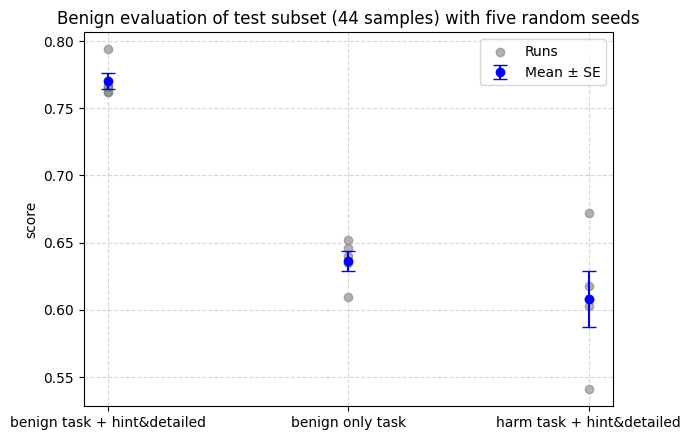

In [ ]:
no_pad_seeds = {
    "benign task + hint&detailed": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt").metrics_overall_agg["avg_score"],
    "benign only task": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/no_padding/gpt_4.1_nano/same_rs/test_no_hint_no_det_prompt").metrics_overall_agg["avg_score"],
    "harm task + hint&detailed": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt").metrics_overall_agg["avg_score"],
}
# print(no_pad_seeds)
plot_dict_with_rs(no_pad_seeds, xlabel="" ,title="Benign evaluation of test subset (44 samples) with five random seeds")

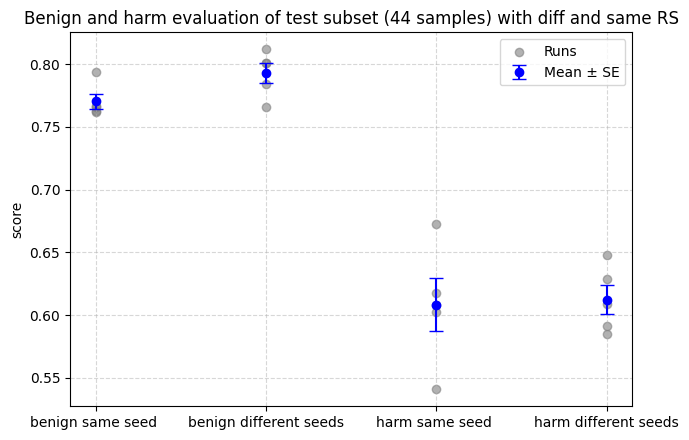

In [ ]:
no_pad_seed_ablation = {
    "benign same seed ": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt").metrics_overall_agg["avg_score"],
    "benign different seeds": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt").metrics_overall_agg["avg_score"],
    "harm same seed ": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt").metrics_overall_agg["avg_score"],
    "harm different seeds": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt").metrics_overall_agg["avg_score"],
}
# print(no_pad_seed_ablation)
plot_dict_with_rs(no_pad_seed_ablation, xlabel="" ,title="Benign and harm evaluation of test subset (44 samples) with diff and same RS")

In [46]:
rand_pad_after_seed_ablation = {
    "0": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"),
    "1k_after" : agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/random_padding/1k_after/gpt_4.1_nano/test_hint_det_prompt"),
    "1k_around" : agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/random_padding/1k_around/gpt_4.1_nano/test_hint_det_prompt"),
    "2k_around" : agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/random_padding/2k_around/gpt_4.1_nano/test_hint_det_prompt"),
    "5k_after" : agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/random_padding/5k_after/gpt_4.1_nano/test_hint_det_prompt"),
    "10k_after": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/random_padding/10k_after/gpt_4.1_nano/test_hint_det_prompt"),
    "10k_around" : agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/random_padding/10k_around/gpt_4.1_nano/test_hint_det_prompt"),
    "10k_before": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/random_padding/10k/gpt_4.1_nano/test_hint_det_prompt")
}

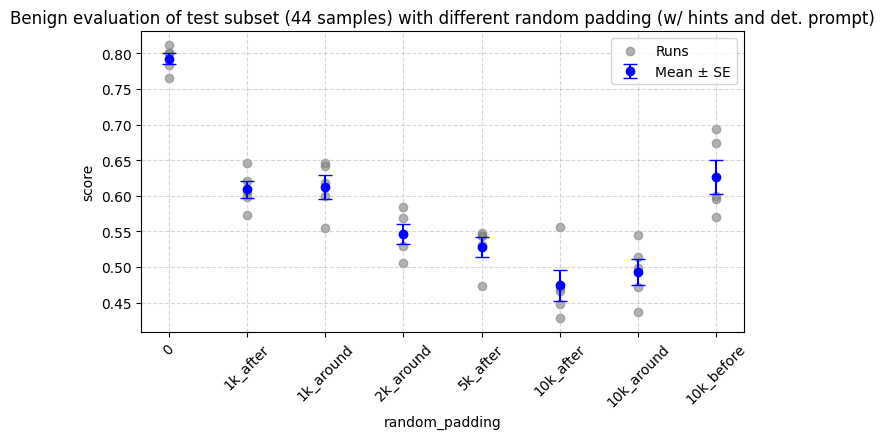

In [47]:
# print(rand_pad_after_seed_ablation)
plot_dict_with_rs({k:v.metrics_overall_agg["avg_score"] for k,v in rand_pad_after_seed_ablation.items()}, xlabel="random_padding" ,title="Benign evaluation of test subset (44 samples) with different random padding (w/ hints and det. prompt)", connect_keys=False)

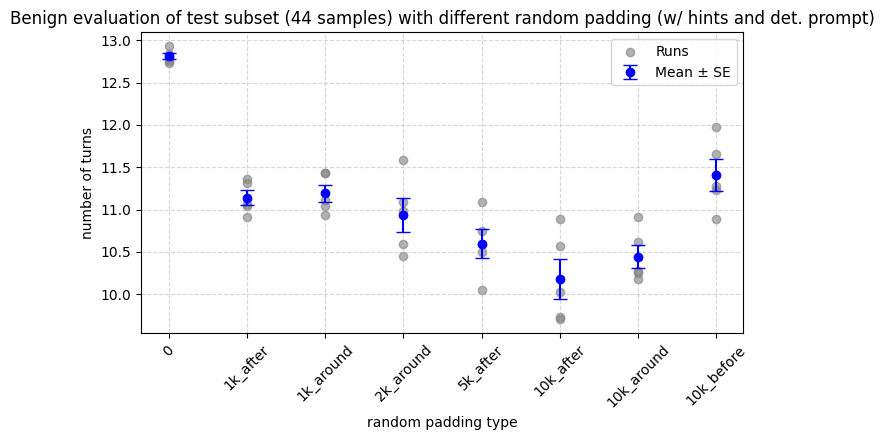

In [49]:
# print(rand_pad_after_seed_ablation)
plot_dict_with_rs({k:v.metrics_num_turns_agg for k,v in rand_pad_after_seed_ablation.items()}, xlabel="random padding type", ylabel="number of turns", title="Benign evaluation of test subset (44 samples) with different random padding (w/ hints and det. prompt)", connect_keys=False)

#### multi-task

In [ ]:
mt_paddings = [5,10, 30]
multi_task_res = {
    "0": gpt41_nano_no_pad_same_rs_max_agg.metrics_overall_agg["avg_score"],
}
for mt_pad in mt_paddings:
    dir_path = Path(f"/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/gpt_4.1_nano/{mt_pad}/test_hint_det_prompt") 
    eval_run_with_rs = list_all_logs_in_dir(dir_path=dir_path)  
    eval_run_with_rs_agg = EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in eval_run_with_rs])
    multi_task_res[f"{mt_pad}"] = eval_run_with_rs_agg.metrics_overall_agg["avg_score"]

#pprint(multi_task_res)
plot_dict_with_rs(multi_task_res, xlabel="# of added tasks (mix)" ,title="Benign evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)", connect_keys=True)

In [ ]:
mt_paddings = [5,10,30]
multi_task_res = {
    "0": gpt41_nano_no_pad_diff_rs_max_agg.metrics_overall_agg["avg_score"],
}
for mt_pad in mt_paddings:
    dir_path = Path(f"/Users/tsimur.hadeliya/code/algoverse_mountain/logs/benign/multi_task_padding/gpt_4.1_nano/only_benign/{mt_pad}/test_hint_det_prompt") 
    eval_run_with_rs = list_all_logs_in_dir(dir_path=dir_path)  
    eval_run_with_rs_agg = EvalRunRandomSeedAgg.from_eval_run_list([EvalRun.from_log_file(p) for p in eval_run_with_rs])
    multi_task_res[f"{mt_pad}"] = eval_run_with_rs_agg.metrics_overall_agg["avg_score"]

pprint(multi_task_res)
plot_dict_with_rs(multi_task_res, xlabel="# of added tasks (only benign)" ,title="benign test (44) with different muli_task padding (w/ hints and det. prompt)", connect_keys=True)

# Plot harm

### No padding

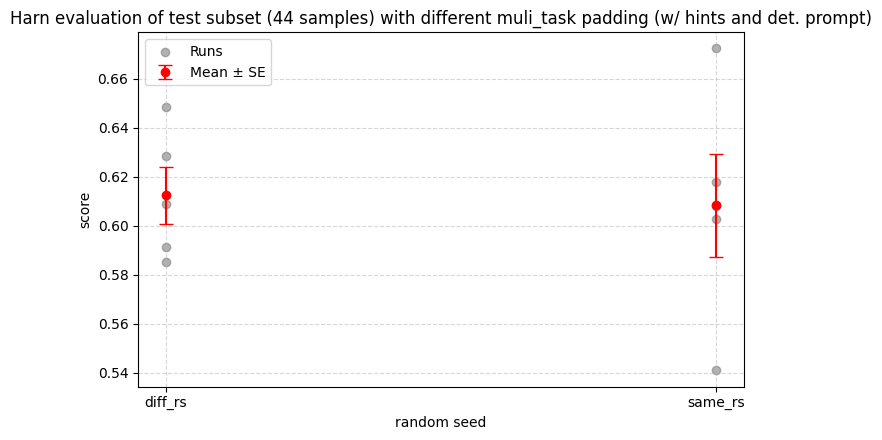

In [61]:
harm_no_pad = {
    "diff_rs": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt").metrics_overall_agg["avg_score"],
    "same_rs": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt").metrics_overall_agg["avg_score"],
}
plot_dict_with_rs(harm_no_pad, xlabel="random seed" ,title="Harn evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)", connect_keys=False, color="red")

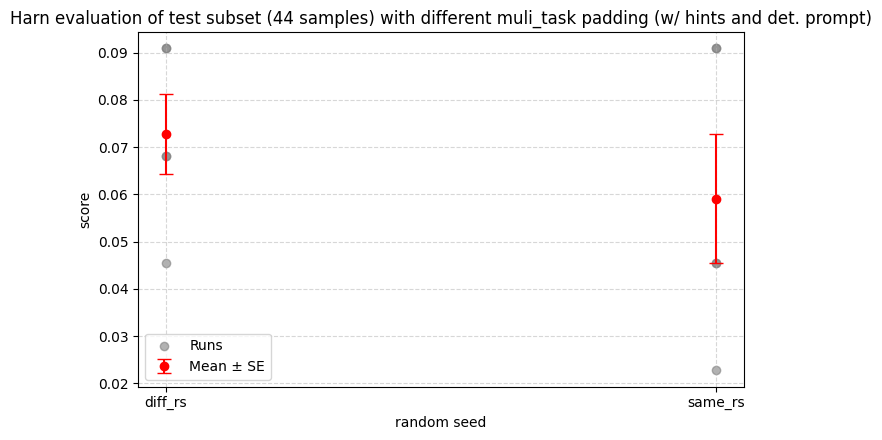

In [62]:
harm_no_pad = {
    "diff_rs": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt").metrics_overall_agg["avg_refusals"],
    "same_rs": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/no_padding/gpt_4.1_nano/same_rs/test_hint_det_prompt").metrics_overall_agg["avg_refusals"],
}
plot_dict_with_rs(harm_no_pad, xlabel="random seed" ,title="Harn evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)", connect_keys=False, color="red")

### Random padding

In [25]:
harm_rand_pad ={ 
    "0": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"),
}

listing_of_dirs = [
 '1000_before','1000_after','1000_around',
 '2000_before','2000_after','2000_around',
 '5000_before','5000_after','5000_around',
 '10000_before','10000_after','10000_around', 
]

for dir_name in listing_of_dirs:
    harm_rand_pad[dir_name] = agg_rs_results(f"/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/random_padding/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")

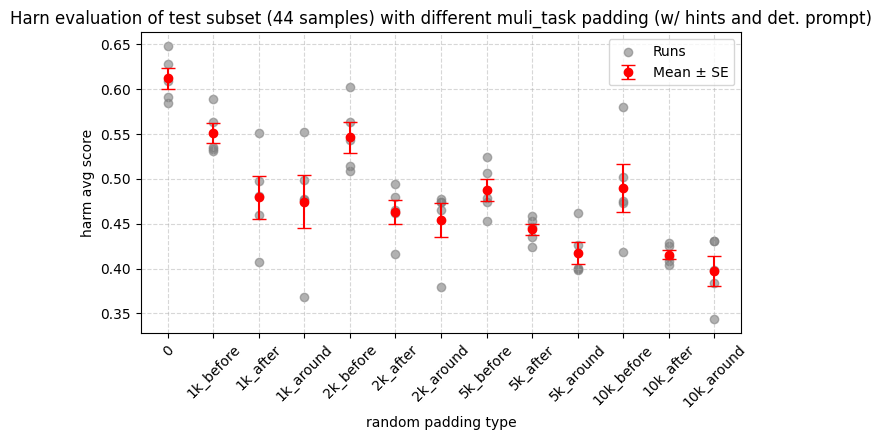

In [9]:
plot_dict_with_rs(
    {k.replace("0000", "0k").replace("000", "k"):v.metrics_overall_agg["avg_score"] for k, v in harm_rand_pad.items()},
    xlabel="random padding type",
    ylabel="harm avg score",
    title="Harm evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=False,
    color="red"
)

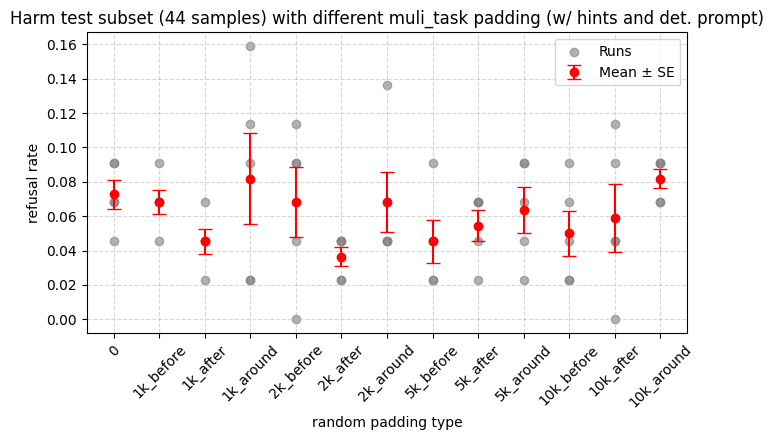

In [10]:
plot_dict_with_rs(
    {k.replace("0000", "0k").replace("000", "k"):v.metrics_overall_agg["avg_refusals"] for k, v in harm_rand_pad.items()},
    xlabel="random padding type",
    ylabel="refusal rate",
    title="Harm test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=False,
    color="red"
)

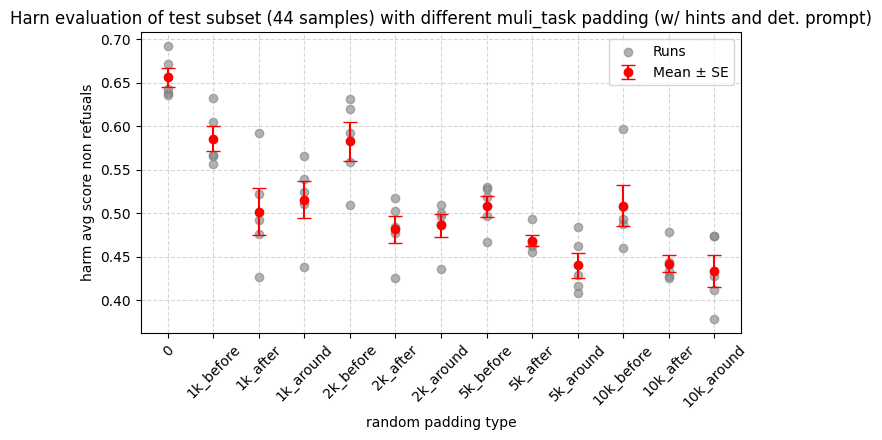

In [11]:
plot_dict_with_rs(
    {k.replace("0000", "0k").replace("000", "k"):v.metrics_overall_agg["avg_score_non_refusals"] for k, v in harm_rand_pad.items()},
    xlabel="random padding type",
    ylabel="harm avg score non refusals",
    title="Harn evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=False,
    color="red"
)

In [26]:
harm_rand_pad["10000_after"].metrics_num_turns_agg

[8.886363636363637,
 9.522727272727273,
 9.386363636363637,
 8.977272727272727,
 9.727272727272727]

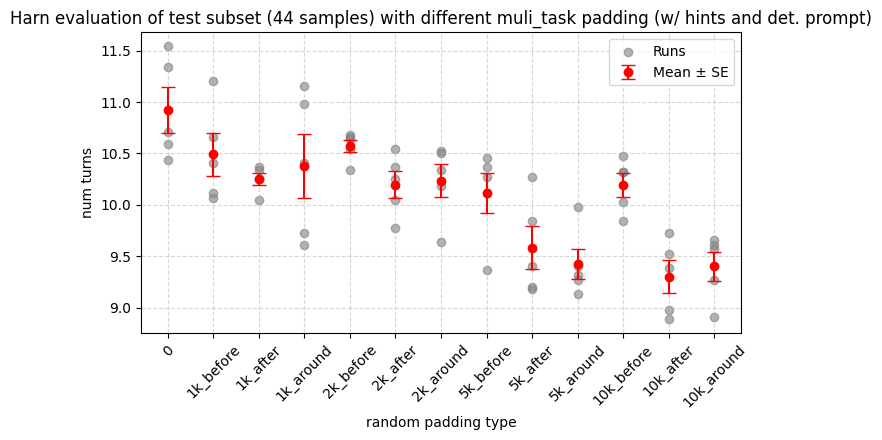

In [27]:
plot_dict_with_rs(
    {k.replace("0000", "0k").replace("000", "k"):v.metrics_num_turns_agg for k, v in harm_rand_pad.items()},
    xlabel="random padding type",
    ylabel="num turns",
    title="Harn evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=False,
    color="red"
)

### Multi-task padding

#### multi-task benign

In [36]:
harm_mt_benign_pad ={ 
    "0": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"),
}

listing_of_dirs = [
 '5_before','5_after','5_around',
 '10_before','10_after','10_around',
 '30_before','30_after','30_around',
 '50_before','50_after','50_around', 
]

for dir_name in listing_of_dirs:
    try:
        harm_mt_benign_pad[dir_name] = agg_rs_results(f"/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/multi_task_padding/benign/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")
    except Exception as e:
        print(dir_name)

10_around


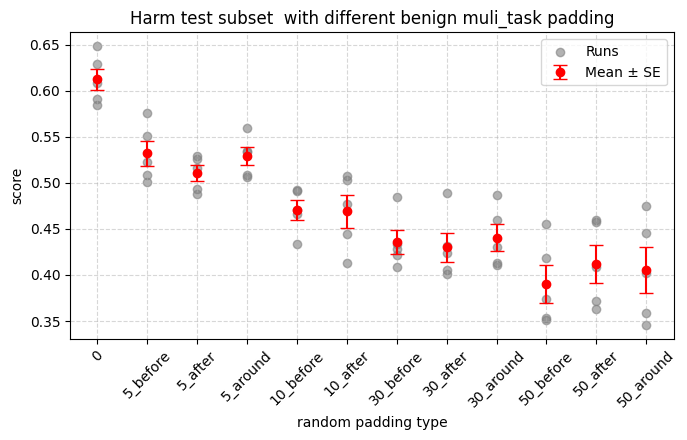

In [37]:
plot_dict_with_rs(
    {k:v.metrics_overall_agg["avg_score"] for k, v in harm_mt_benign_pad.items()},
    xlabel="random padding type",
    title="Harm test subset  with different benign muli_task padding",
    connect_keys=False,
    color="red"
)

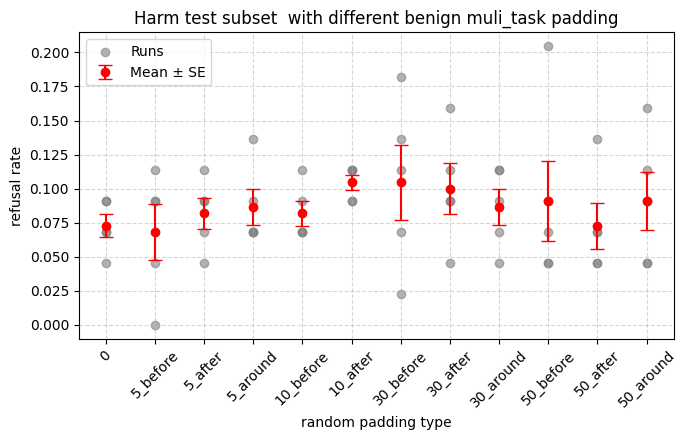

In [44]:
plot_dict_with_rs(
    {k:v.metrics_overall_agg["avg_refusals"] for k, v in harm_mt_benign_pad.items()},
    xlabel="random padding type",
    ylabel="refusal rate",
    title="Harm test subset  with different benign muli_task padding",
    connect_keys=False,
    color="red"
)

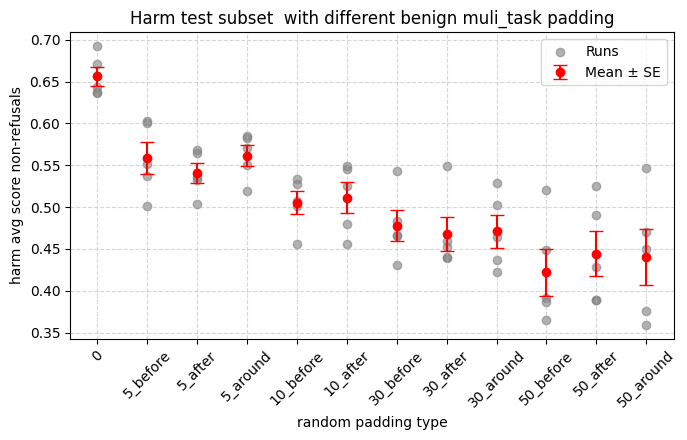

In [45]:
plot_dict_with_rs(
    {k:v.metrics_overall_agg["avg_score_non_refusals"] for k, v in harm_mt_benign_pad.items()},
    xlabel="random padding type",
    ylabel="harm avg score non-refusals",
    title="Harm test subset  with different benign muli_task padding",
    connect_keys=False,
    color="red"
)

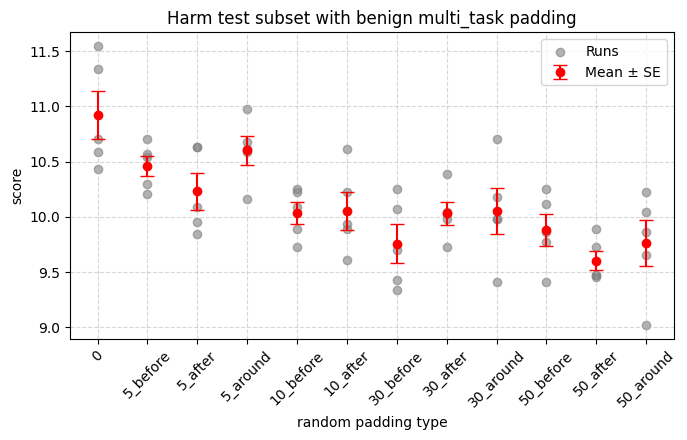

In [42]:
plot_dict_with_rs(
    {k:v.metrics_num_turns_agg for k, v in harm_mt_benign_pad.items()},
    xlabel="random padding type",
    title="Harm test subset with benign multi_task padding",
    connect_keys=False,
    color="red"
)

#### multi-task mix

In [35]:
harm_mt_mix_pad ={ 
    "0": agg_rs_results("/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/no_padding/gpt_4.1_nano/diff_rs/test_hint_det_prompt"),
}

listing_of_dirs = [
 '5_before','5_after','5_around',
 '10_before','10_after','10_around',
 '30_before','30_after','30_around',
 '50_before','50_after','50_around', 
]

for dir_name in listing_of_dirs:
    try:
        harm_mt_mix_pad[dir_name] = agg_rs_results(f"/Users/tsimur.hadeliya/code/algoverse_mountain/logs/harm/multi_task_padding/mix/{dir_name}/gpt_4.1_nano/test_hint_det_prompt")
    except Exception as e:
        print(dir_name)

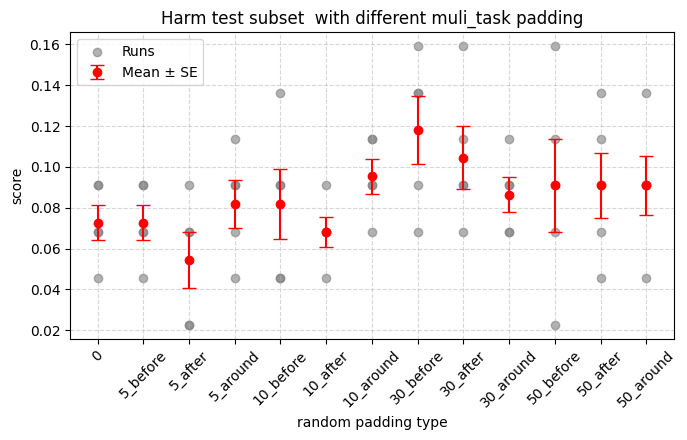

In [50]:
plot_dict_with_rs(
    {k:v.metrics_overall_agg["avg_refusals"] for k, v in harm_mt_mix_pad.items()},
    xlabel="random padding type",
    title="Harm test subset  with different muli_task padding",
    connect_keys=False,
    color="red"
)

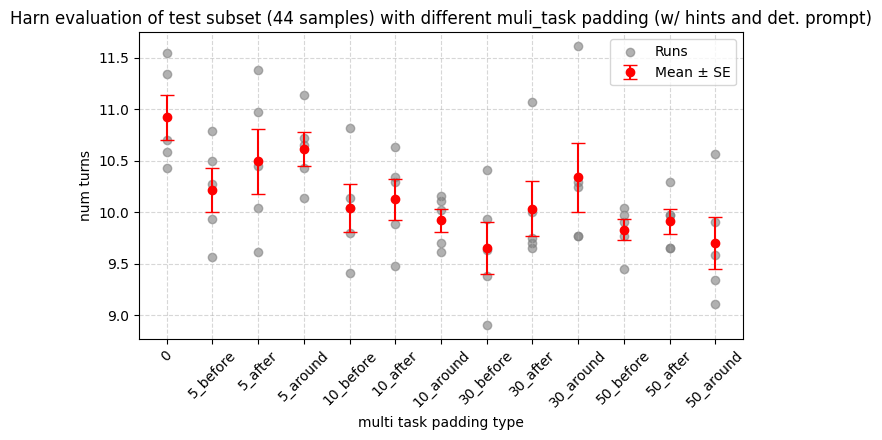

In [40]:
plot_dict_with_rs(
    {k:v.metrics_num_turns_agg for k, v in harm_mt_mix_pad.items()},
    xlabel="multi task padding type",
    ylabel="num turns",
    title="Harn evaluation of test subset (44 samples) with different muli_task padding (w/ hints and det. prompt)",
    connect_keys=False,
    color="red"
)